Project: AI-Powered Global Food Supply Chain & Commodity Market Intelligence Platform

Objective: Develop and evaluate forecasting models for four global food commodity benchmarks using historical monthly prices.

In [1]:
# Step 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
import pandas as pd

df = pd.read_csv("CFCO_Commodity_Prices_Long_Format.csv")

df["Date"] = pd.to_datetime(df["Date"])

df = df.sort_values(
    ["commodity_code", "Date"]
).reset_index(drop=True)

print("Dataset shape:", df.shape)
print(df.head())
print(df["commodity_code"].value_counts())

Dataset shape: (280, 3)
        Date commodity_code  price_usd_mt
0 2021-01-01          MAIZE         234.5
1 2021-02-01          MAIZE         245.2
2 2021-03-01          MAIZE         245.2
3 2021-04-01          MAIZE         268.2
4 2021-05-01          MAIZE         305.3
commodity_code
MAIZE           70
RICE_THAI_5     70
SOYBEANS        70
WHEAT_US_HRW    70
Name: count, dtype: int64


In [3]:
print("COLUMN NAMES:")
print(df.columns.tolist())

print("\nMISSING VALUES:")
print(df.isnull().sum())

print("\nDUPLICATE RECORDS:")
print(df.duplicated(
    subset=["Date", "commodity_code"]
).sum())

print("\nRECORDS PER COMMODITY:")
print(df["commodity_code"].value_counts())

print("\nDATE RANGE:")
print(df["Date"].min(), "to", df["Date"].max())

COLUMN NAMES:
['Date', 'commodity_code', 'price_usd_mt']

MISSING VALUES:
Date              0
commodity_code    0
price_usd_mt      0
dtype: int64

DUPLICATE RECORDS:
0

RECORDS PER COMMODITY:
commodity_code
MAIZE           70
RICE_THAI_5     70
SOYBEANS        70
WHEAT_US_HRW    70
Name: count, dtype: int64

DATE RANGE:
2021-01-01 00:00:00 to 2026-10-01 00:00:00


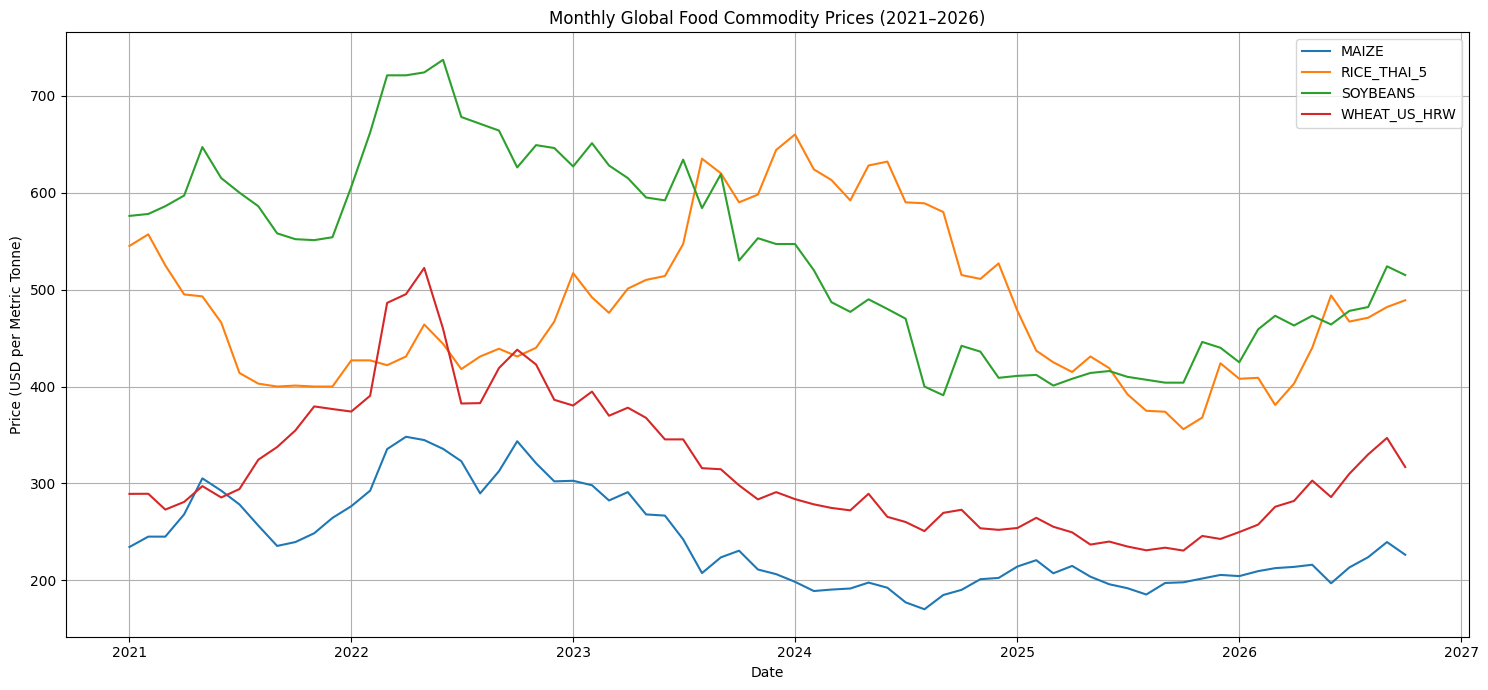

In [4]:
import matplotlib.pyplot as plt

commodities = df["commodity_code"].unique()

plt.figure(figsize=(15, 7))

for commodity in commodities:
    commodity_data = df[
        df["commodity_code"] == commodity
    ]

    plt.plot(
        commodity_data["Date"],
        commodity_data["price_usd_mt"],
        label=commodity
    )

plt.title("Monthly Global Food Commodity Prices (2021–2026)")
plt.xlabel("Date")
plt.ylabel("Price (USD per Metric Tonne)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

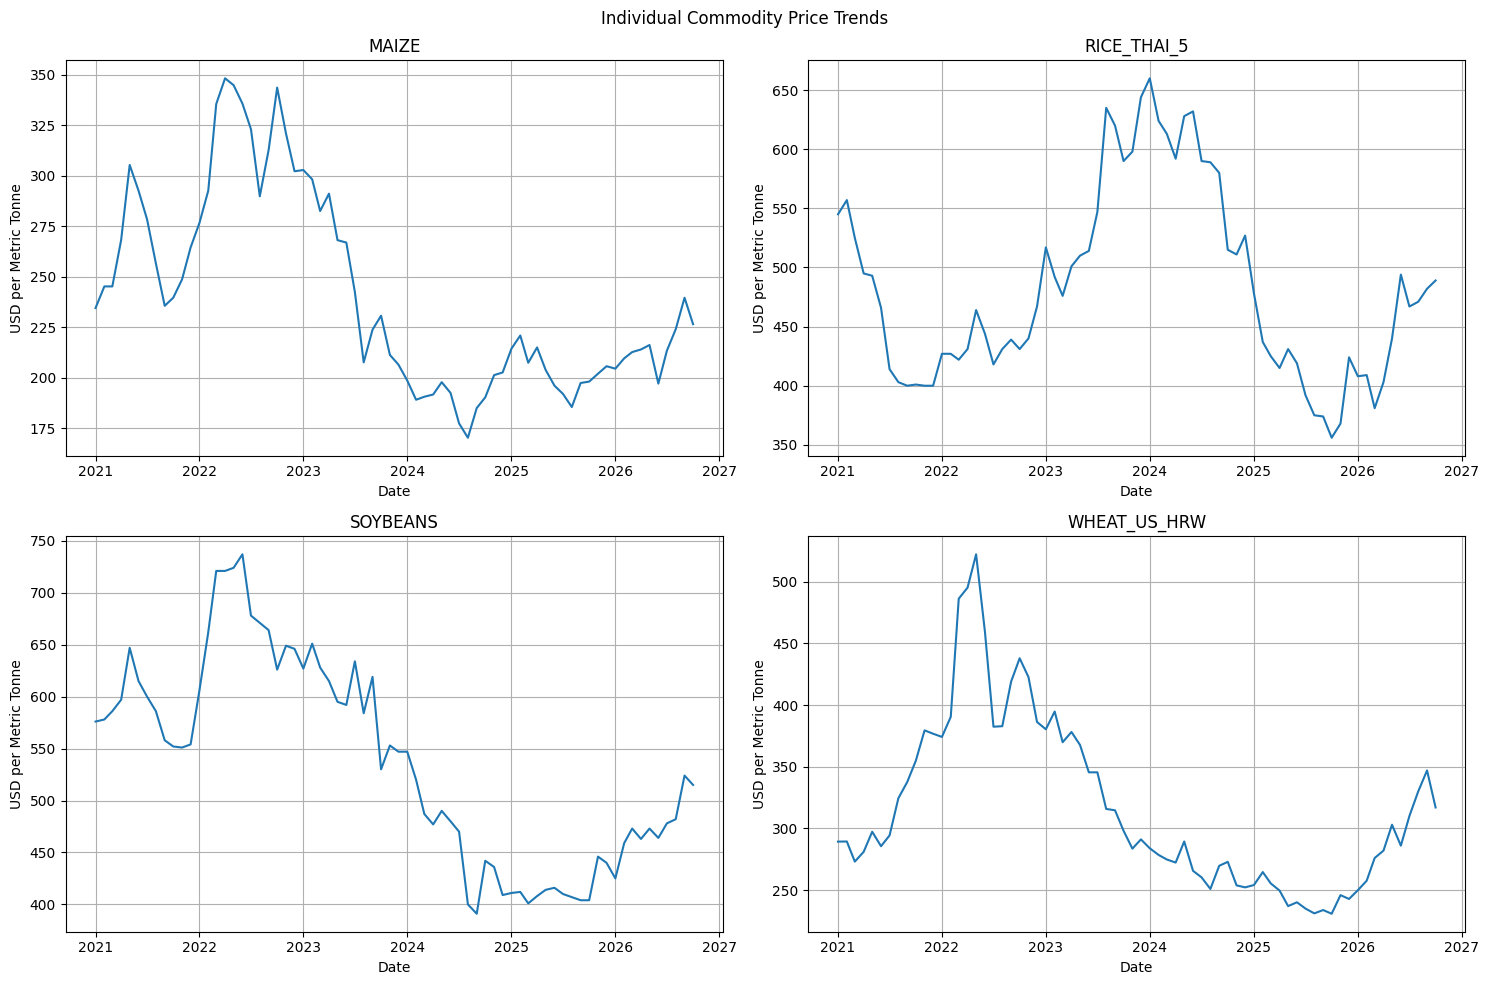

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for commodity, ax in zip(commodities, axes.flatten()):
    commodity_data = df[
        df["commodity_code"] == commodity
    ]

    ax.plot(
        commodity_data["Date"],
        commodity_data["price_usd_mt"]
    )

    ax.set_title(commodity)
    ax.set_xlabel("Date")
    ax.set_ylabel("USD per Metric Tonne")
    ax.grid(True)

plt.suptitle("Individual Commodity Price Trends")
plt.tight_layout()
plt.show()

In [6]:
# Calculate monthly percentage change for each commodity

df["monthly_return_pct"] = (
    df.groupby("commodity_code")["price_usd_mt"]
    .pct_change(fill_method=None) * 100
)

print(df.head(10))

        Date commodity_code  price_usd_mt  monthly_return_pct
0 2021-01-01          MAIZE         234.5                 NaN
1 2021-02-01          MAIZE         245.2            4.562900
2 2021-03-01          MAIZE         245.2            0.000000
3 2021-04-01          MAIZE         268.2            9.380098
4 2021-05-01          MAIZE         305.3           13.832960
5 2021-06-01          MAIZE         292.6           -4.159843
6 2021-07-01          MAIZE         278.4           -4.853042
7 2021-08-01          MAIZE         256.6           -7.830460
8 2021-09-01          MAIZE         235.6           -8.183944
9 2021-10-01          MAIZE         239.6            1.697793


In [7]:
volatility_report = (
    df.groupby("commodity_code")["monthly_return_pct"]
    .agg(["mean", "std", "min", "max"])
    .reset_index()
)

volatility_report.columns = [
    "Commodity",
    "Average_Monthly_Return_Pct",
    "Monthly_Volatility_Pct",
    "Minimum_Monthly_Return_Pct",
    "Maximum_Monthly_Return_Pct"
]

volatility_report["Annualised_Volatility_Pct"] = (
    volatility_report["Monthly_Volatility_Pct"] * (12 ** 0.5)
)

volatility_report = volatility_report.sort_values(
    "Annualised_Volatility_Pct",
    ascending=False
)

print(volatility_report.round(2))

      Commodity  Average_Monthly_Return_Pct  Monthly_Volatility_Pct  \
3  WHEAT_US_HRW                        0.31                    6.11   
0         MAIZE                        0.13                    5.97   
1   RICE_THAI_5                       -0.00                    5.67   
2      SOYBEANS                       -0.03                    5.09   

   Minimum_Monthly_Return_Pct  Maximum_Monthly_Return_Pct  \
3                      -16.78                       24.53   
0                      -14.36                       14.66   
1                      -11.21                       16.09   
2                      -14.89                       13.04   

   Annualised_Volatility_Pct  
3                      21.16  
0                      20.68  
1                      19.64  
2                      17.65  


In [8]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

results = []

for commodity in df["commodity_code"].unique():

    # Select one commodity
    commodity_df = df[
        df["commodity_code"] == commodity
    ].sort_values("Date").copy()

    # First 58 months for training
    train = commodity_df.iloc[:-12].copy()

    # Last 12 months for testing
    test = commodity_df.iloc[-12:].copy()

    # Naive forecast: previous month's actual price
    test["Naive_Forecast"] = (
        commodity_df["price_usd_mt"]
        .shift(1)
        .loc[test.index]
    )

    # Evaluate forecasting accuracy
    mae = mean_absolute_error(
        test["price_usd_mt"],
        test["Naive_Forecast"]
    )

    rmse = np.sqrt(
        mean_squared_error(
            test["price_usd_mt"],
            test["Naive_Forecast"]
        )
    )

    mape = np.mean(
        np.abs(
            (test["price_usd_mt"] - test["Naive_Forecast"])
            / test["price_usd_mt"]
        )
    ) * 100

    results.append({
        "Commodity": commodity,
        "Training_Observations": len(train),
        "Testing_Observations": len(test),
        "MAE": mae,
        "RMSE": rmse,
        "MAPE_Pct": mape
    })

naive_results = pd.DataFrame(results)

print(naive_results.round(2))

      Commodity  Training_Observations  Testing_Observations    MAE   RMSE  \
0         MAIZE                     58                    12   7.93  10.13   
1   RICE_THAI_5                     58                    12  22.92  28.87   
2      SOYBEANS                     58                    12  17.42  21.82   
3  WHEAT_US_HRW                     58                    12  15.53  17.36   

   MAPE_Pct  
0      3.68  
1      5.26  
2      3.70  
3      5.26  


In [9]:
seasonal_results = []

for commodity in df["commodity_code"].unique():

    commodity_df = df[
        df["commodity_code"] == commodity
    ].sort_values("Date").copy()

    train = commodity_df.iloc[:-12].copy()
    test = commodity_df.iloc[-12:].copy()

    # Use the price from 12 months earlier
    test["Seasonal_Forecast"] = (
        commodity_df["price_usd_mt"]
        .shift(12)
        .loc[test.index]
    )

    mae = mean_absolute_error(
        test["price_usd_mt"],
        test["Seasonal_Forecast"]
    )

    rmse = np.sqrt(
        mean_squared_error(
            test["price_usd_mt"],
            test["Seasonal_Forecast"]
        )
    )

    mape = np.mean(
        np.abs(
            (test["price_usd_mt"] - test["Seasonal_Forecast"])
            / test["price_usd_mt"]
        )
    ) * 100

    seasonal_results.append({
        "Commodity": commodity,
        "Training_Observations": len(train),
        "Testing_Observations": len(test),
        "MAE": mae,
        "RMSE": rmse,
        "MAPE_Pct": mape
    })

seasonal_results = pd.DataFrame(seasonal_results)

print(seasonal_results.round(2))

      Commodity  Training_Observations  Testing_Observations    MAE   RMSE  \
0         MAIZE                     58                    12  14.59  20.30   
1   RICE_THAI_5                     58                    12  74.67  85.99   
2      SOYBEANS                     58                    12  59.17  67.35   
3  WHEAT_US_HRW                     58                    12  47.22  60.42   

   MAPE_Pct  
0      6.55  
1     17.08  
2     12.25  
3     15.19  


In [10]:
naive_comparison = naive_results[
    ["Commodity", "MAE", "RMSE", "MAPE_Pct"]
].copy()

seasonal_comparison = seasonal_results[
    ["Commodity", "MAE", "RMSE", "MAPE_Pct"]
].copy()

comparison = naive_comparison.merge(
    seasonal_comparison,
    on="Commodity",
    suffixes=("_Naive", "_Seasonal")
)

print(comparison.round(2))

      Commodity  MAE_Naive  RMSE_Naive  MAPE_Pct_Naive  MAE_Seasonal  \
0         MAIZE       7.93       10.13            3.68         14.59   
1   RICE_THAI_5      22.92       28.87            5.26         74.67   
2      SOYBEANS      17.42       21.82            3.70         59.17   
3  WHEAT_US_HRW      15.53       17.36            5.26         47.22   

   RMSE_Seasonal  MAPE_Pct_Seasonal  
0          20.30               6.55  
1          85.99              17.08  
2          67.35              12.25  
3          60.42              15.19  


In [11]:
def create_features(commodity_df):

    commodity_df = commodity_df.sort_values("Date").copy()

    # Historical prices
    for lag in [1, 2, 3, 6, 12]:
        commodity_df[f"lag_{lag}"] = (
            commodity_df["price_usd_mt"].shift(lag)
        )

    # Average of the previous three months
    commodity_df["rolling_mean_3"] = (
        commodity_df["price_usd_mt"]
        .shift(1)
        .rolling(window=3)
        .mean()
    )

    return commodity_df


print("Historical feature function created successfully!")

Historical feature function created successfully!


In [12]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

rf_results = []

for commodity in df["commodity_code"].unique():

    commodity_df = df[
        df["commodity_code"] == commodity
    ].sort_values("Date").copy()

    # Create historical features
    commodity_df = create_features(commodity_df)

    # Remove rows without sufficient historical data
    commodity_df = commodity_df.dropna().copy()

    # Chronological split: first 58 months vs final 12
    train_end_date = df[
        df["commodity_code"] == commodity
    ].sort_values("Date").iloc[-13]["Date"]

    train = commodity_df[
        commodity_df["Date"] <= train_end_date
    ]

    test = commodity_df[
        commodity_df["Date"] > train_end_date
    ]

    feature_columns = [
        "lag_1",
        "lag_2",
        "lag_3",
        "lag_6",
        "lag_12",
        "rolling_mean_3"
    ]

    X_train = train[feature_columns]
    y_train = train["price_usd_mt"]

    X_test = test[feature_columns]
    y_test = test["price_usd_mt"]

    # Train Random Forest
    model = RandomForestRegressor(
        n_estimators=300,
        max_depth=4,
        min_samples_leaf=2,
        random_state=42
    )

    model.fit(X_train, y_train)

    # Generate predictions
    predictions = model.predict(X_test)

    # Evaluate performance
    mae = mean_absolute_error(y_test, predictions)

    rmse = np.sqrt(
        mean_squared_error(y_test, predictions)
    )

    mape = np.mean(
        np.abs((y_test - predictions) / y_test)
    ) * 100

    rf_results.append({
        "Commodity": commodity,
        "Training_Rows": len(train),
        "Testing_Rows": len(test),
        "MAE": mae,
        "RMSE": rmse,
        "MAPE_Pct": mape
    })

rf_results = pd.DataFrame(rf_results)

print(rf_results.round(2))

      Commodity  Training_Rows  Testing_Rows    MAE   RMSE  MAPE_Pct
0         MAIZE             46            12  10.79  13.83      4.92
1   RICE_THAI_5             46            12  24.19  29.59      5.58
2      SOYBEANS             46            12  49.25  52.90     10.30
3  WHEAT_US_HRW             46            12  32.29  38.22     10.63


In [13]:
model_comparison = (
    naive_results[
        ["Commodity", "MAE", "RMSE", "MAPE_Pct"]
    ]
    .merge(
        seasonal_results[
            ["Commodity", "MAE", "RMSE", "MAPE_Pct"]
        ],
        on="Commodity",
        suffixes=("_Naive", "_Seasonal")
    )
    .merge(
        rf_results[
            ["Commodity", "MAE", "RMSE", "MAPE_Pct"]
        ],
        on="Commodity"
    )
    .rename(columns={
        "MAE": "MAE_RandomForest",
        "RMSE": "RMSE_RandomForest",
        "MAPE_Pct": "MAPE_RandomForest"
    })
)

print(model_comparison.round(2))

      Commodity  MAE_Naive  RMSE_Naive  MAPE_Pct_Naive  MAE_Seasonal  \
0         MAIZE       7.93       10.13            3.68         14.59   
1   RICE_THAI_5      22.92       28.87            5.26         74.67   
2      SOYBEANS      17.42       21.82            3.70         59.17   
3  WHEAT_US_HRW      15.53       17.36            5.26         47.22   

   RMSE_Seasonal  MAPE_Pct_Seasonal  MAE_RandomForest  RMSE_RandomForest  \
0          20.30               6.55             10.79              13.83   
1          85.99              17.08             24.19              29.59   
2          67.35              12.25             49.25              52.90   
3          60.42              15.19             32.29              38.22   

   MAPE_RandomForest  
0               4.92  
1               5.58  
2              10.30  
3              10.63  


In [14]:
# Create final model selection report

final_comparison = model_comparison.copy()

def select_best_model(row):

    scores = {
        "Naive": row["MAPE_Pct_Naive"],
        "Seasonal Naive": row["MAPE_Pct_Seasonal"],
        "Random Forest": row["MAPE_RandomForest"]
    }

    return min(scores, key=scores.get)


final_comparison["Best_Model"] = (
    final_comparison.apply(select_best_model, axis=1)
)

final_comparison["Best_MAPE_Pct"] = final_comparison[
    [
        "MAPE_Pct_Naive",
        "MAPE_Pct_Seasonal",
        "MAPE_RandomForest"
    ]
].min(axis=1)

print(final_comparison[
    ["Commodity", "Best_Model", "Best_MAPE_Pct"]
].round(2))

      Commodity Best_Model  Best_MAPE_Pct
0         MAIZE      Naive           3.68
1   RICE_THAI_5      Naive           5.26
2      SOYBEANS      Naive           3.70
3  WHEAT_US_HRW      Naive           5.26


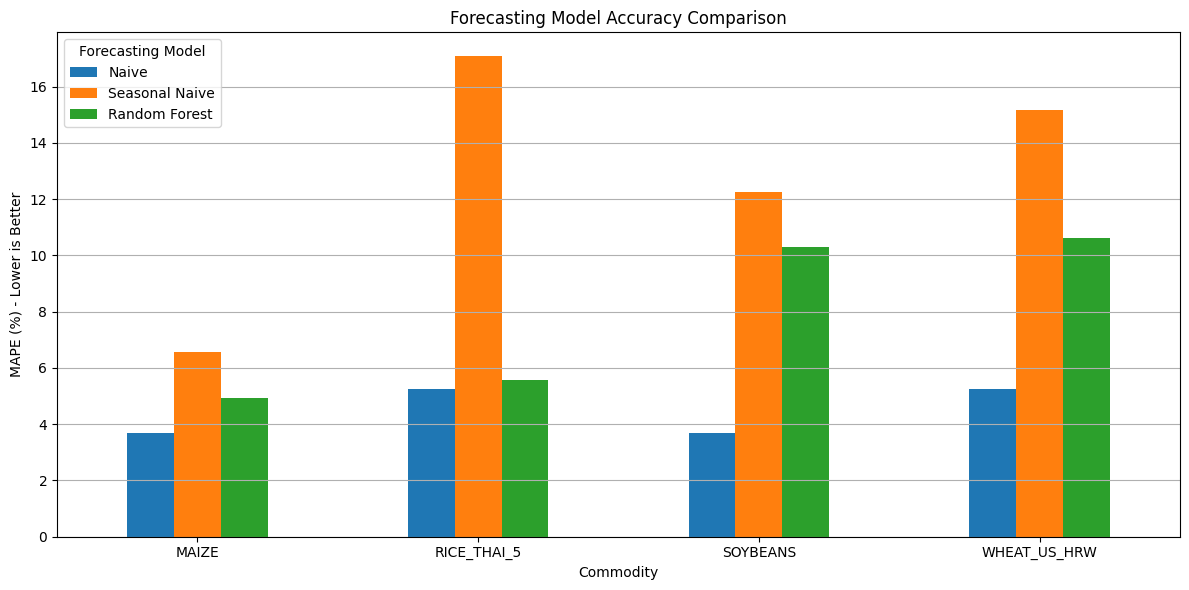

In [15]:
import matplotlib.pyplot as plt

plot_data = final_comparison.set_index("Commodity")[
    [
        "MAPE_Pct_Naive",
        "MAPE_Pct_Seasonal",
        "MAPE_RandomForest"
    ]
]

plot_data.columns = [
    "Naive",
    "Seasonal Naive",
    "Random Forest"
]

plot_data.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Forecasting Model Accuracy Comparison")
plt.ylabel("MAPE (%) - Lower is Better")
plt.xlabel("Commodity")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.legend(title="Forecasting Model")
plt.tight_layout()
plt.show()

In [16]:
import os

output_folder = "/content/"

final_comparison.to_csv(
    output_folder + "CFCO_Forecasting_Model_Comparison.csv",
    index=False
)

volatility_report.to_csv(
    output_folder + "CFCO_Commodity_Volatility_Report.csv",
    index=False
)

print("Forecasting reports exported successfully!")

Forecasting reports exported successfully!


In [17]:
def evaluate_rolling_models(
    commodity_df,
    initial_train=36,
    test_size=3,
    step_size=3
):

    commodity_df = commodity_df.sort_values(
        "Date"
    ).reset_index(drop=True)

    results = []

    # Move through the historical data
    for origin in range(
        initial_train,
        len(commodity_df) - test_size + 1,
        step_size
    ):

        train = commodity_df.iloc[:origin].copy()

        test = commodity_df.iloc[
            origin:origin + test_size
        ].copy()

        # Naive: last known training price
        naive_predictions = [
            train["price_usd_mt"].iloc[-1]
        ] * test_size

        # Seasonal naive: price from 12 months earlier
        seasonal_predictions = []

        for date in test["Date"]:
            historical_date = date - pd.DateOffset(months=12)

            historical_price = commodity_df.loc[
                commodity_df["Date"] == historical_date,
                "price_usd_mt"
            ]

            if historical_price.empty:
                seasonal_predictions.append(np.nan)
            else:
                seasonal_predictions.append(
                    historical_price.iloc[0]
                )

        # Prepare recursive Random Forest forecasts
        history = train["price_usd_mt"].tolist()

        feature_columns = [
            "lag_1", "lag_2", "lag_3",
            "lag_6", "lag_12", "rolling_mean_3"
        ]

        rf_predictions = []

        for _ in range(test_size):

            features = {
                "lag_1": history[-1],
                "lag_2": history[-2],
                "lag_3": history[-3],
                "lag_6": history[-6],
                "lag_12": history[-12],
                "rolling_mean_3": np.mean(history[-3:])
            }

            feature_df = pd.DataFrame(
                [features],
                columns=feature_columns
            )

            model = RandomForestRegressor(
                n_estimators=300,
                max_depth=4,
                min_samples_leaf=2,
                random_state=42
            )

            train_features = create_features(train).dropna()

            model.fit(
                train_features[feature_columns],
                train_features["price_usd_mt"]
            )

            prediction = model.predict(feature_df)[0]

            rf_predictions.append(prediction)

            # Add prediction to history for next forecast
            history.append(prediction)

        actual = test["price_usd_mt"].values

        predictions = {
            "Naive": naive_predictions,
            "Seasonal_Naive": seasonal_predictions,
            "Random_Forest": rf_predictions
        }

        for model_name, forecast in predictions.items():

            forecast = np.array(forecast)

            if np.isnan(forecast).any():
                continue

            mae = mean_absolute_error(actual, forecast)

            rmse = np.sqrt(
                mean_squared_error(actual, forecast)
            )

            mape = np.mean(
                np.abs((actual - forecast) / actual)
            ) * 100

            results.append({
                "Window_Start": test["Date"].iloc[0],
                "Commodity": commodity_df["commodity_code"].iloc[0],
                "Model": model_name,
                "MAE": mae,
                "RMSE": rmse,
                "MAPE_Pct": mape
            })

    return pd.DataFrame(results)


print("Rolling-origin evaluation function created successfully!")

Rolling-origin evaluation function created successfully!


In [18]:
rolling_results = []

for commodity in df["commodity_code"].unique():

    commodity_df = df[
        df["commodity_code"] == commodity
    ].copy()

    commodity_result = evaluate_rolling_models(
        commodity_df,
        initial_train=36,
        test_size=3,
        step_size=3
    )

    rolling_results.append(commodity_result)

rolling_results = pd.concat(
    rolling_results,
    ignore_index=True
)

print("Rolling-origin validation completed!")

print("\nTotal evaluation records:", len(rolling_results))

print("\nResults by commodity and model:")
print(rolling_results.round(2).to_string(index=False))

Rolling-origin validation completed!

Total evaluation records: 132

Results by commodity and model:
Window_Start    Commodity          Model    MAE   RMSE  MAPE_Pct
  2024-01-01        MAIZE          Naive  13.73  14.35      7.17
  2024-01-01        MAIZE Seasonal_Naive 101.73 101.99     52.79
  2024-01-01        MAIZE  Random_Forest  28.05  28.48     14.61
  2024-04-01        MAIZE          Naive   3.40   4.35      1.73
  2024-04-01        MAIZE Seasonal_Naive  81.37  82.38     42.01
  2024-04-01        MAIZE  Random_Forest   3.28   3.52      1.70
  2024-07-01        MAIZE          Naive  14.93  16.09      8.53
  2024-07-01        MAIZE Seasonal_Naive  47.03  48.72     26.51
  2024-07-01        MAIZE  Random_Forest  16.01  17.08      9.14
  2024-10-01        MAIZE          Naive  13.07  14.18      6.52
  2024-10-01        MAIZE Seasonal_Naive  18.10  24.13      9.37
  2024-10-01        MAIZE  Random_Forest  17.01  17.95      8.52
  2025-01-01        MAIZE          Naive  11.63  12.87

In [19]:
rolling_summary = (
    rolling_results
    .groupby(["Commodity", "Model"])
    [["MAE", "RMSE", "MAPE_Pct"]]
    .mean()
    .reset_index()
)

rolling_summary = rolling_summary.sort_values(
    ["Commodity", "MAPE_Pct"]
)

print(rolling_summary.round(2).to_string(index=False))

   Commodity          Model    MAE   RMSE  MAPE_Pct
       MAIZE          Naive  10.32  11.50      5.07
       MAIZE  Random_Forest  14.85  15.72      7.28
       MAIZE Seasonal_Naive  31.48  33.14     16.05
 RICE_THAI_5          Naive  37.24  39.63      7.94
 RICE_THAI_5  Random_Forest  39.80  43.06      8.63
 RICE_THAI_5 Seasonal_Naive 116.09 118.04     25.55
    SOYBEANS          Naive  22.15  25.65      5.02
    SOYBEANS  Random_Forest  38.81  42.08      8.43
    SOYBEANS Seasonal_Naive  87.33  90.09     19.64
WHEAT_US_HRW          Naive  13.69  15.21      4.90
WHEAT_US_HRW  Random_Forest  18.52  19.63      6.71
WHEAT_US_HRW Seasonal_Naive  49.34  51.09     17.95


In [20]:
# Export detailed rolling-origin results

rolling_results.to_csv(
    "CFCO_Rolling_Origin_Detailed_Results.csv",
    index=False
)

# Export average model performance

rolling_summary.to_csv(
    "CFCO_Rolling_Origin_Model_Summary.csv",
    index=False
)

print("Both rolling-origin reports exported successfully!")

Both rolling-origin reports exported successfully!


In [21]:
import pandas as pd
import numpy as np

# Make sure the data is sorted
df = df.sort_values(
    ["commodity_code", "Date"]
).reset_index(drop=True)

forecast_results = []

# Forecast six months ahead
forecast_horizon = 6

for commodity in df["commodity_code"].unique():

    # Select individual commodity
    commodity_df = df[
        df["commodity_code"] == commodity
    ].sort_values("Date").copy()

    # Get latest observed price and date
    latest_price = commodity_df[
        "price_usd_mt"
    ].iloc[-1]

    latest_date = commodity_df[
        "Date"
    ].iloc[-1]

    # Calculate historical monthly percentage returns
    historical_returns = (
        commodity_df["price_usd_mt"]
        .pct_change(fill_method=None)
        .dropna()
        .values
    )

    # Generate future dates
    future_dates = pd.date_range(
        start=latest_date + pd.DateOffset(months=1),
        periods=forecast_horizon,
        freq="MS"
    )

    # Generate forecast and uncertainty ranges
    np.random.seed(42)

    simulations = 10000

    simulated_prices = np.zeros(
        (simulations, forecast_horizon)
    )

    current_prices = np.full(
        simulations, latest_price
    )

    for month in range(forecast_horizon):

        sampled_returns = np.random.choice(
            historical_returns,
            size=simulations,
            replace=True
        )

        current_prices = current_prices * (
            1 + sampled_returns
        )

        simulated_prices[:, month] = current_prices

    # Create monthly forecast output
    for month in range(forecast_horizon):

        forecast_results.append({
            "Commodity": commodity,
            "Forecast_Date": future_dates[month],
            "Latest_Actual_Price": latest_price,
            "Naive_Forecast": latest_price,
            "Lower_80": np.percentile(
                simulated_prices[:, month], 10
            ),
            "Upper_80": np.percentile(
                simulated_prices[:, month], 90
            ),
            "Lower_95": np.percentile(
                simulated_prices[:, month], 2.5
            ),
            "Upper_95": np.percentile(
                simulated_prices[:, month], 97.5
            )
        })

forecast_df = pd.DataFrame(forecast_results)

print("Six-month forecasting completed!")

print(
    forecast_df.round(2).to_string(index=False)
)

Six-month forecasting completed!
   Commodity Forecast_Date  Latest_Actual_Price  Naive_Forecast  Lower_80  Upper_80  Lower_95  Upper_95
       MAIZE    2026-11-01                226.5           226.5    208.73    244.40    203.22    257.83
       MAIZE    2026-12-01                226.5           226.5    203.07    251.95    192.27    265.65
       MAIZE    2027-01-01                226.5           226.5    198.26    258.30    184.57    274.84
       MAIZE    2027-02-01                226.5           226.5    193.57    262.97    179.20    284.12
       MAIZE    2027-03-01                226.5           226.5    190.35    267.89    174.24    292.64
       MAIZE    2027-04-01                226.5           226.5    187.28    272.11    170.04    300.24
 RICE_THAI_5    2026-11-01                489.0           489.0    457.49    522.01    434.43    563.41
 RICE_THAI_5    2026-12-01                489.0           489.0    441.18    539.01    420.88    575.43
 RICE_THAI_5    2027-01-01     

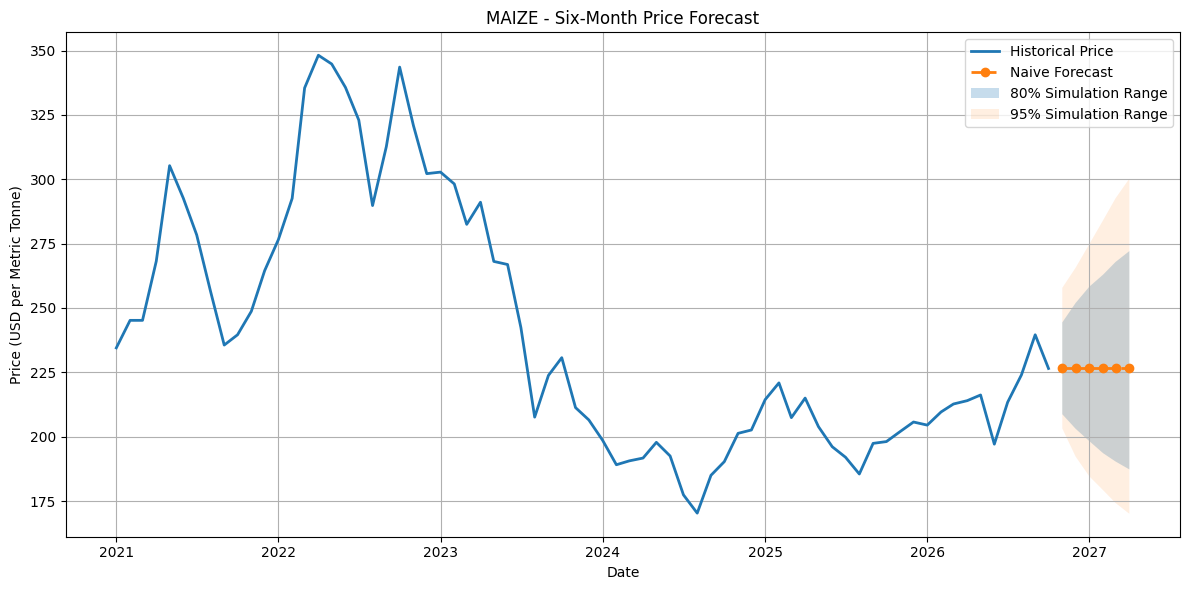

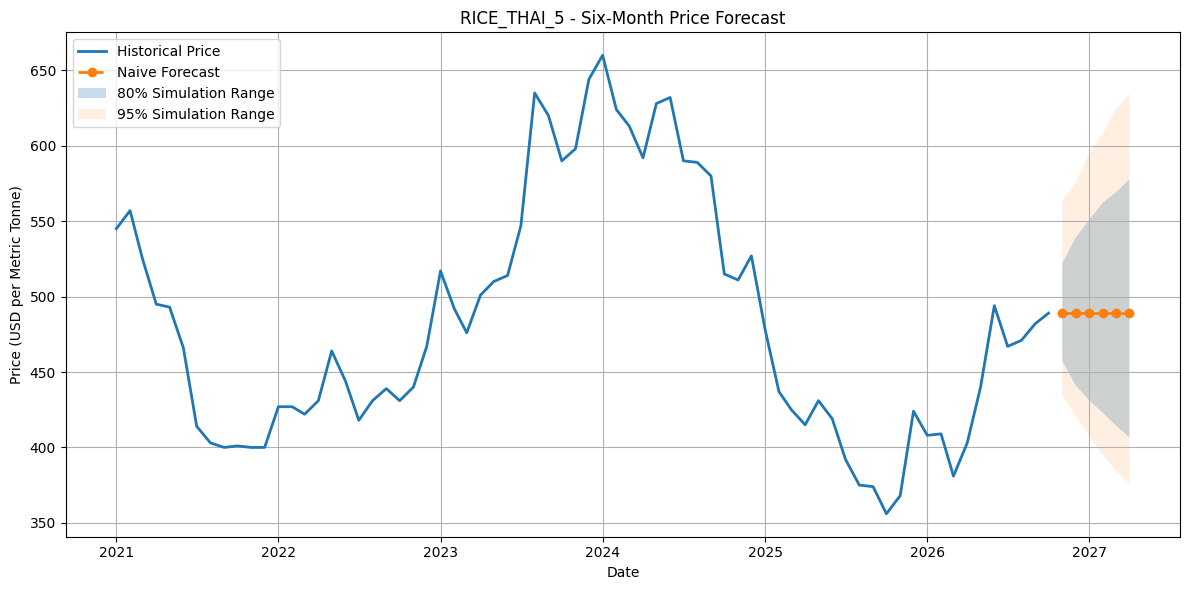

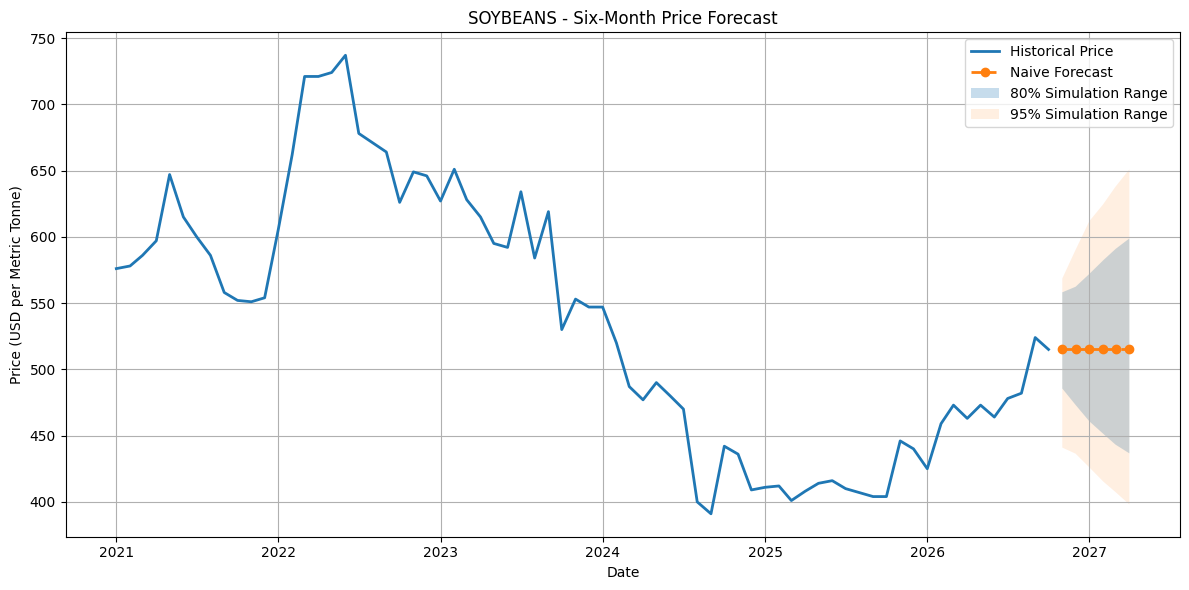

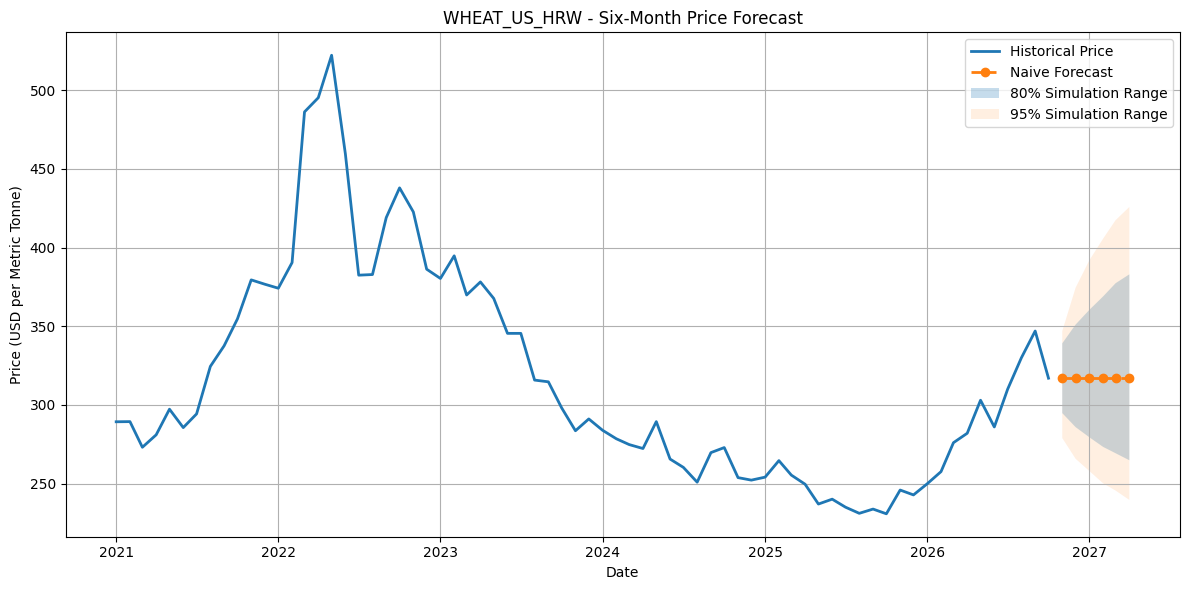

In [22]:
import matplotlib.pyplot as plt

commodities = forecast_df["Commodity"].unique()

for commodity in commodities:

    # Historical prices
    historical = df[
        df["commodity_code"] == commodity
    ].sort_values("Date")

    # Future forecasts
    future = forecast_df[
        forecast_df["Commodity"] == commodity
    ].sort_values("Forecast_Date")

    plt.figure(figsize=(12, 6))

    # Historical price line
    plt.plot(
        historical["Date"],
        historical["price_usd_mt"],
        label="Historical Price",
        linewidth=2
    )

    # Forecast point estimate
    plt.plot(
        future["Forecast_Date"],
        future["Naive_Forecast"],
        label="Naive Forecast",
        linestyle="--",
        marker="o",
        linewidth=2
    )

    # 80% simulation range
    plt.fill_between(
        future["Forecast_Date"],
        future["Lower_80"],
        future["Upper_80"],
        alpha=0.25,
        label="80% Simulation Range"
    )

    # 95% simulation range
    plt.fill_between(
        future["Forecast_Date"],
        future["Lower_95"],
        future["Upper_95"],
        alpha=0.12,
        label="95% Simulation Range"
    )

    plt.title(
        f"{commodity} - Six-Month Price Forecast"
    )

    plt.xlabel("Date")
    plt.ylabel("Price (USD per Metric Tonne)")

    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [23]:
with pd.ExcelWriter(
    "CFCO_Six_Month_Commodity_Forecasts.xlsx",
    engine="openpyxl"
) as writer:

    forecast_df.to_excel(
        writer,
        sheet_name="Six_Month_Forecasts",
        index=False
    )

    volatility_report.to_excel(
        writer,
        sheet_name="Historical_Volatility",
        index=False
    )

    rolling_summary.to_excel(
        writer,
        sheet_name="Model_Validation",
        index=False
    )

print("Forecasting Excel workbook created successfully!")

Forecasting Excel workbook created successfully!
